In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

import numpy as np

# Trap function to avoid division by zero (0/0) when V approaches singularities
def vtrap(num, denom, rate_scale):
    val = denom / rate_scale
    # Use linear approximation when denominator is close to 0
    return np.where(np.abs(val) < 1e-6,
                    num / (rate_scale * (1.0 + 0.5 * val)),
                    num / (np.exp(val) - 1.0))

def compute_rates(V, VT):
    # Ion channel alpha and beta rates (Page 7 of preprint)
    # Sodium (m, h)
    a_m = vtrap(-0.32 * (V - VT - 13.0), -(V - VT - 13.0), 4.0)
    b_m = vtrap(0.28 * (V - VT - 40.0), (V - VT - 40.0), 5.0)
    a_h = 0.128 * np.exp(-(V - VT - 17.0) / 18.0)
    b_h = 4.0 / (np.exp(-(V - VT - 40.0) / 5.0) + 1.0)

    # Potassium (n)
    a_n = vtrap(-0.032 * (V - VT - 15.0), -(V - VT - 15.0), 5.0)
    b_n = 0.5 * np.exp(-(V - VT - 10.0) / 40.0)

    # Calcium (q, s)
    a_q = vtrap(0.055 * (-27.0 - V), (-27.0 - V), 3.8)
    b_q = 0.94 * np.exp((-75.0 - V) / 17.0)
    a_s = 0.000457 * np.exp((-13.0 - V) / 50.0)
    b_s = 0.0065 / (np.exp((-15.0 - V) / 28.0) + 1.0)

    # Slow M-type Potassium (p)
    p_inf = 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))
    # p_tau is computed per neuron type using tau_max

    return a_m, b_m, a_h, b_h, a_n, b_n, a_q, b_q, a_s, b_s, p_inf

def euler_step_hh(V, m, h, n, p, q, s, r, I_in, I_el, I_ch, params, dt=0.01):
    VT = params['VT']
    C = params['C']
    tau_max = params['tau_max']

    # 1. Update rates
    a_m, b_m, a_h, b_h, a_n, b_n, a_q, b_q, a_s, b_s, p_inf = compute_rates(V, VT)
    p_tau = tau_max / (3.3 * np.exp((V + 35.0) / 20.0) + np.exp(-(V + 35.0) / 20.0))

    # 2. Update gating variables (dm/dt = alpha*(1-m) - beta*m)
    dm = a_m * (1.0 - m) - b_m * m # activation rate and disactivation rate. At equilibium di = 0
    dh = a_h * (1.0 - h) - b_h * h
    dn = a_n * (1.0 - n) - b_n * n
    dq = a_q * (1.0 - q) - b_q * q
    ds = a_s * (1.0 - s) - b_s * s
    dp = (p_inf - p) / p_tau

    # 3. Update synaptic receptor variable r (Eq. 5)
    tau_rise, tau_decay = 0.5, 8.0
    dr = ((1.0 / tau_rise) - (1.0 / tau_decay)) * ((1.0 - r) / (1.0 + np.exp(-V - 20.0))) - (r / tau_decay)

    # 4. Ionic currents
    I_L  = params['gL']  * (V - params['EL'])
    I_Na = params['gNa'] * (m**3) * h * (V - params['ENa'])
    I_K  = params['gK']  * (n**4) * (V - params['EK'])
    I_M  = params['gM']  * p * (V - params['EK'])
    I_Ca = params['gCa'] * (q**2) * s * (V - params['ECa'])

    # 5. Membrane potential update (Eq. 3)
    dV = (I_in - I_L - I_Na - I_K - I_M - I_Ca + I_el + I_ch) / C

    # Advance state
    return (V + dt * dV,
            m + dt * dm,
            h + dt * dh,
            n + dt * dn,
            p + dt * dp,
            q + dt * dq,
            s + dt * ds,
            r + dt * dr)


In [ ]:
# Generate patterns then compute Willshaw Matrix

def generate_patterns(B, P, M):
  ''' B = number of blocks (certain number of each type of neuron)
  P = number of patterns (dimension of the memory)
  M = number of active blocks per pattern (to enforce sparsity)'''
  patterns = np.zeros((P,B), dtype=int)
  for p in range(P):
    active_blocks = np.random.choice(B, M, replace=False) # generates 1s for just some of the blocks
    patterns[p, active_blocks] = 1
  return patterns # numpy array with p dimensional memories and B blocks total of which M are used per memory

def willshaw(patterns, B):
  coactivity = patterns.T @ patterns # calculates whether neurons fire together
  W = (coactivity > 0).astype(float) # converts those that do fire together as 1s
  np.fill_diagonal(W, 0) # prevents self-coupling
  return W # Willshaw matrix instead of weight matrix to prevent blowing up weights




In [ ]:
# Connect back to full neuron scale rather than just having blocks

def build_network_matrices_fast(B, W, g_RSA_RSA = 0.08, g_FS_RSA = 1.2): # changed from a nested for loop to a brute force method to save time
    N = 5 * B
    A_el = np.zeros((N, N))
    A_ch = np.zeros((N, N))

    # Weights & conductances
    w_el_val = 0.5
    # g_RSA_RSA = 0.08 # Adjust to modulate how long the memory is sustained
    # g_FS_RSA  = 1.2 # Adjust to modulate inhibitory factor
    g_FS_FS   = 0.003

    # 1. Electrical Synapses: Identical 5x5 block tiled along the diagonal
    # Indices: 0: IB, 1: RSA1, 2: RSA2, 3: FS, 4: RSA_out
    block_el = np.zeros((5, 5))
    block_el[1, 0] = w_el_val  # IB -> RSA1
    block_el[2, 1] = w_el_val  # RSA1 -> RSA2
    block_el[3, 1] = w_el_val  # RSA1 -> FS
    block_el[4, 2] = w_el_val  # RSA2 -> RSA_out

    # Tile it for all B blocks with Kronecker product (zero loops!)
    A_el = np.kron(np.eye(B), block_el)

    # 2. Chemical Synapses: Direct slicing using block strides
    # RSA2 of block i is at index: 5*i + 2
    # RSA1 of block j is at index: 5*j + 1
    # FS   of block i is at index: 5*i + 3

    rsa2_indices = np.arange(B) * 5 + 2
    rsa1_indices = np.arange(B) * 5 + 1
    fs_indices   = np.arange(B) * 5 + 3

    # Excitatory: RSA2_i -> RSA1_j where W[i, j] == 1
    # np.ix_ allows direct 2D submatrix indexing
    A_ch[np.ix_(rsa1_indices, rsa2_indices)] = g_RSA_RSA * W.T

    # Inhibitory: FS_i -> RSA2_j where W[i, j] == 0 (and i != j)
    inv_W = (1.0 - W) - np.eye(B)
    A_ch[np.ix_(rsa1_indices, fs_indices)] = g_FS_RSA * inv_W.T

    # Disinhibition: FS_i -> FS_j (constant across all i != j)
    all_off_diag = np.ones((B, B)) - np.eye(B)
    A_ch[np.ix_(fs_indices, fs_indices)] = g_FS_FS * all_off_diag.T

    idx = lambda block, cell_type: block * 5 + cell_type
    return A_el, A_ch, idx


def create_neuron_parameters(B):
    N = 5 * B

    # Initialize arrays for all parameters
    params = {
        'C': np.zeros(N), 'gL': np.zeros(N), 'EL': np.zeros(N),
        'gNa': np.zeros(N), 'ENa': np.zeros(N),
        'gK': np.zeros(N), 'EK': np.zeros(N),
        'gM': np.zeros(N), 'tau_max': np.zeros(N),
        'gCa': np.zeros(N), 'ECa': np.zeros(N),
        'VT': np.full(N, -56.2),
        'V_syn': np.zeros(N)
    }

    # Biophysical profiles from Table 1
    type_params = {
        0: {'C': 1.0, 'gL': 0.01,   'EL': -70.0, 'gNa': 50.0, 'ENa': 50.0, 'gK': 5.0,  'EK': -90.0, 'gM': 0.03,  'tau_max': 608.0, 'gCa': 0.2, 'ECa': 120.0, 'V_syn': 20.0},  # IB
        1: {'C': 1.0, 'gL': 0.0205, 'EL': -70.3, 'gNa': 56.0, 'ENa': 56.0, 'gK': 6.0,  'EK': -90.0, 'gM': 0.075, 'tau_max': 608.0, 'gCa': 0.0, 'ECa': 0.0,   'V_syn': 20.0},  # RSA1
        2: {'C': 1.0, 'gL': 0.0205, 'EL': -70.3, 'gNa': 56.0, 'ENa': 56.0, 'gK': 6.0,  'EK': -90.0, 'gM': 0.075, 'tau_max': 608.0, 'gCa': 0.0, 'ECa': 0.0,   'V_syn': 20.0},  # RSA2
        3: {'C': 0.5, 'gL': 0.015,  'EL': -70.0, 'gNa': 56.0, 'ENa': 50.0, 'gK': 10.0, 'EK': -90.0, 'gM': 0.0,   'tau_max': 1.0,   'gCa': 0.0, 'ECa': 0.0,   'V_syn': -80.0}, # FS
        4: {'C': 1.0, 'gL': 0.0205, 'EL': -70.3, 'gNa': 56.0, 'ENa': 56.0, 'gK': 6.0,  'EK': -90.0, 'gM': 0.075, 'tau_max': 608.0, 'gCa': 0.0, 'ECa': 0.0,   'V_syn': 20.0}   # RSA_out
    }

    for b in range(B):
        for c_type, vals in type_params.items():
            k = b * 5 + c_type
            for p_name, val in vals.items():
                params[p_name][k] = val

    return params


In [ ]:
def run_simulation(T_total_ms, dt, B, patterns, stim_schedule, params, A_el, A_ch, idx):
    """
    stim_schedule: list of tuples -> (start_ms, end_ms, pattern_index, current_amplitude)
    """
    N = 5 * B # 5 neurons per block
    steps = int(T_total_ms / dt)
    time = np.linspace(0, T_total_ms, steps)

    # Initial conditions (Equation 14 in preprint)
    V = np.full(N, -70.0)
    m = np.zeros(N) # 1 dim N
    h = np.zeros(N)
    n = np.zeros(N)
    p = np.zeros(N)
    q = np.zeros(N)
    s = np.zeros(N)
    r = np.zeros(N)

    # Pre-calculate electrical out-weights for speed
    A_el_sum = np.sum(A_el, axis=1) # N x 1

    # Record output spikes: array of lists for each block's RSA_out
    spike_times = {b: [] for b in range(B)} # B number of empty lists since each block stores on output per turn

    # Optional: downsampled recording of voltages for plotting
    recorded_V_out = np.zeros((steps // 10, B))
    rec_times = time[::10]

    for step in range(steps):
        t_now = step * dt # float

        # 1. Build I_in vector for input IB neurons
        I_in = np.zeros(N) # N,
        for (t_start, t_end, pat_idx, amp) in stim_schedule:
            if t_start <= t_now <= t_end:
                active_blocks = np.where(patterns[pat_idx] == 1)[0]
                for b in active_blocks:
                    I_in[idx(b, 0)] += amp  # inject into IB neuron

        # 2. Synaptic currents
        I_el = (A_el @ V) - (A_el_sum * V) # (NxN) @ (N,) - (N,) * (N,) = (N,)

        # Fast vectorization for chemical synapses
        # --- With this fast matrix-vector form: ---
        s = A_ch @ (r * params['V_syn'])
        g_total = A_ch @ r
        I_ch = s - g_total * V


        # 3. Previous V to detect spikes (> 0 mV crossing)
        V_prev = V.copy()

        # 4. Integrate one Euler step
        V, m, h, n, p, q, s, r = euler_step_hh(
            V, m, h, n, p, q, s, r, I_in, I_el, I_ch, params, dt=dt
        )

        # 5. Detect spikes on RSA_out neurons (cell_type = 4)
        for b in range(B):
            out_idx = idx(b, 4) # Refers to cell type 4
            if V_prev[out_idx] <= 0.0 and V[out_idx] > 0.0: # If previous voltage of cell type 4 is negative and this one crosses 0
                spike_times[b].append(t_now) # then consider this a spike time for neuron of cell type 4 on block b

        if step % 10 == 0: # for recording equal dims of x and y for the plot
            rec_idx = step // 10
            for b in range(B):
                recorded_V_out[rec_idx, b] = V[idx(b, 4)]

    return time, spike_times, rec_times, recorded_V_out # in O(N^2)


In [ ]:
import matplotlib.pyplot as plt

def compute_overlap(time, spike_times, pattern, B, delta_t=7.0):
    """
    Computes time-dependent overlap m_mu(t) following Equation (13) in the paper.
    """
    # Convert pattern from {0, 1} to {-1, +1}
    xi_scaled = 2 * pattern - 1  # shape (B,)

    m_t = np.zeros(len(time))

    # Pre-convert spike_times dict to sorted arrays for fast lookup
    spikes_arr = [np.array(spike_times[b]) for b in range(B)]

    for t_idx, t in enumerate(time):
        eta = np.zeros(B)
        for b in range(B):
            # Check if any spike occurred within |t - t_spike| <= delta_t
            if len(spikes_arr[b]) > 0:
                min_diff = np.min(np.abs(spikes_arr[b] - t))
                if min_diff <= delta_t:
                    eta[b] = 1.0

        eta_scaled = 2 * eta - 1  # shape (B,)
        m_t[t_idx] = np.mean(xi_scaled * eta_scaled)

    return m_t

def plot_experiment_results(time, spike_times, patterns, title="Memory Simulation"):
    B = len(spike_times)

    # Compute overlap for Memory 0 and Memory 1
    m0 = compute_overlap(time, spike_times, patterns[0], B)
    m1 = compute_overlap(time, spike_times, patterns[1], B)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2]})

    # --- 1. Overlap Curves ---
    ax1.plot(time, m0, label='Overlap with Memory 1 ($m_1$)', color='crimson', lw=2)
    ax1.plot(time, m1, label='Overlap with Memory 2 ($m_2$)', color='dodgerblue', lw=2)
    ax1.axhline(1.0, color='gray', linestyle='--', alpha=0.6)
    ax1.axhline(0.0, color='gray', linestyle=':', alpha=0.6)
    ax1.set_ylabel('$m_\mu(t)$')
    ax1.set_ylim(-0.2, 1.1)
    ax1.set_title(title)
    ax1.legend(loc='upper right')
    ax1.grid(True, alpha=0.3)

    # --- 2. Spike Raster Plot ---
    # Highlight which blocks belong to which memory
    mem1_blocks = set(np.where(patterns[0] == 1)[0])
    mem2_blocks = set(np.where(patterns[1] == 1)[0])

    for b in range(B):
        times = spike_times[b]
        if len(times) > 0:
            # Color code spikes by memory identity
            if b in mem1_blocks and b in mem2_blocks:
                color = 'purple'  # Shared blocks
            elif b in mem1_blocks:
                color = 'crimson'
            elif b in mem2_blocks:
                color = 'dodgerblue'
            else:
                color = 'black'

            ax2.scatter(times, [b] * len(times), color=color, s=15, marker='|')

    ax2.set_ylabel('Block Index (0 to B-1)')
    ax2.set_xlabel('Time (ms)')
    ax2.set_ylim(-1, B)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


<>:43: SyntaxWarning: invalid escape sequence '\m'
<>:43: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1008/3236300145.py:43: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$m_\mu(t)$')


# Run the Simulation

In [ ]:
# Simulation
B = 100 # blocks of neurons consisting of an input neuron from an external stimulus, an RSA_1 that connects to a fast spiking and an RSA_2 which connects to an output RSA
patterns = generate_patterns(B, P=70, M=10) # <-- Change
W = willshaw(patterns, 10)
A_el, A_ch, idx = build_network_matrices_fast(B,W, g_RSA_RSA=0.1, g_FS_RSA = 0.75) # Change RSA RSA and FS RSA to adjust excitatory and inhibitory sensitivity
params = create_neuron_parameters(B)


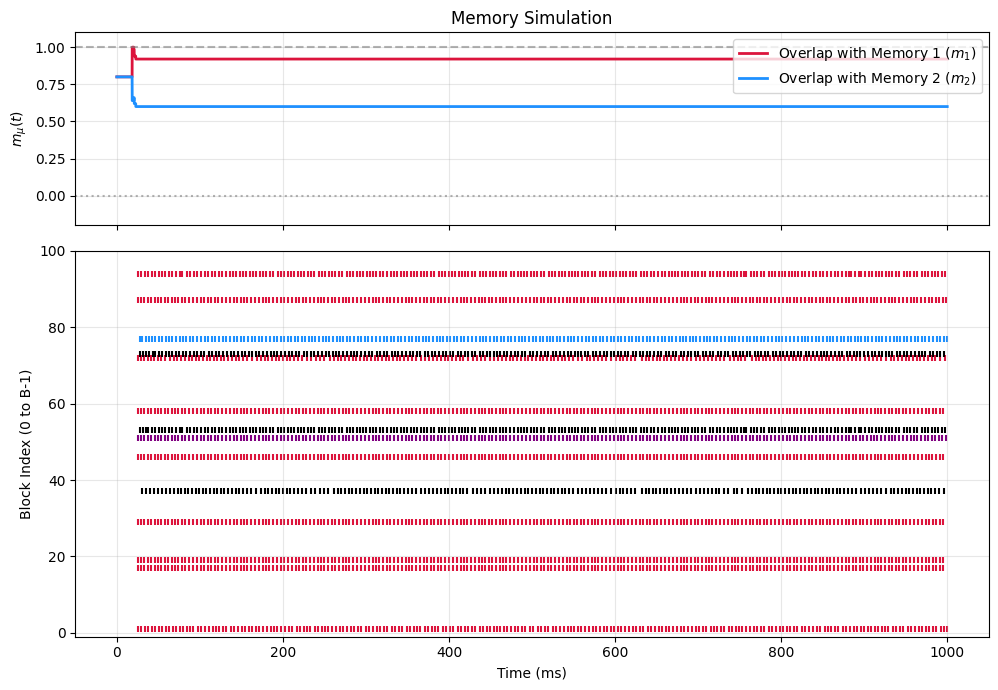

In [ ]:
# Fire memory 1
T_total_ms = 1000
dt = .01
schedule_mem1 = [(0.0, 30.0, 0, 1.0)]
time, spike_times, rec_times, recorded_V_out = run_simulation(T_total_ms, dt, B, patterns, schedule_mem1, params, A_el, A_ch, idx)
plot_experiment_results(time, spike_times, patterns, title="Memory Simulation")

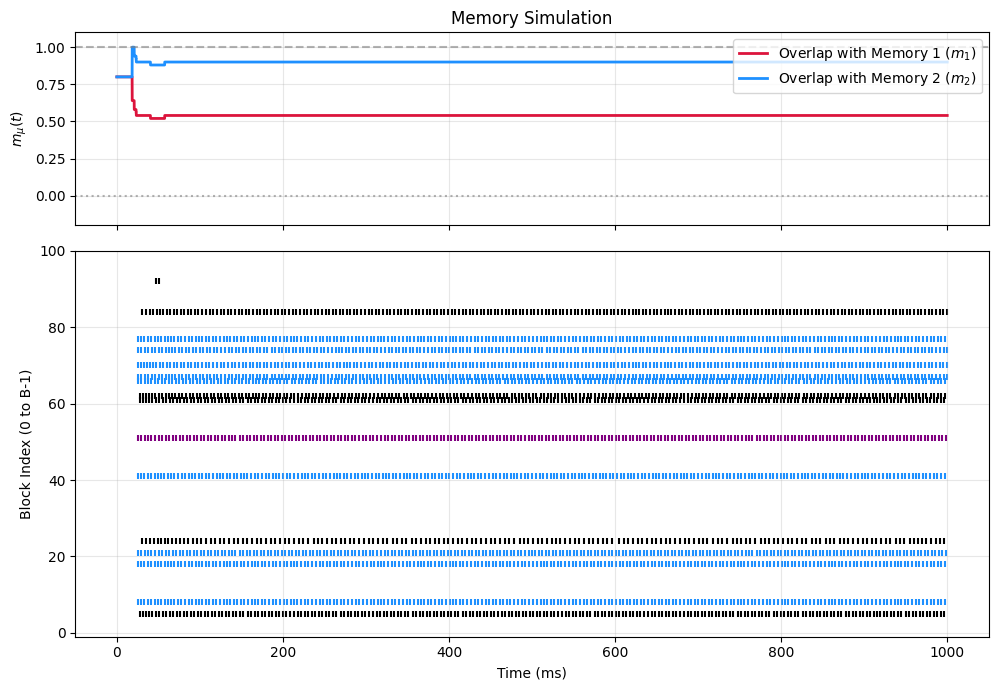

In [ ]:
# Confirm with second memory that different blocks are used in different memories
T_total_ms = 1000
dt = .01
schedule_mem2 = [(0.0, 30.0, 1, 1.0)]
time, spike_times, rec_times, recorded_V_out = run_simulation(T_total_ms, dt, B, patterns, schedule_mem2, params, A_el, A_ch, idx)
plot_experiment_results(time, spike_times, patterns, title="Memory Simulation")

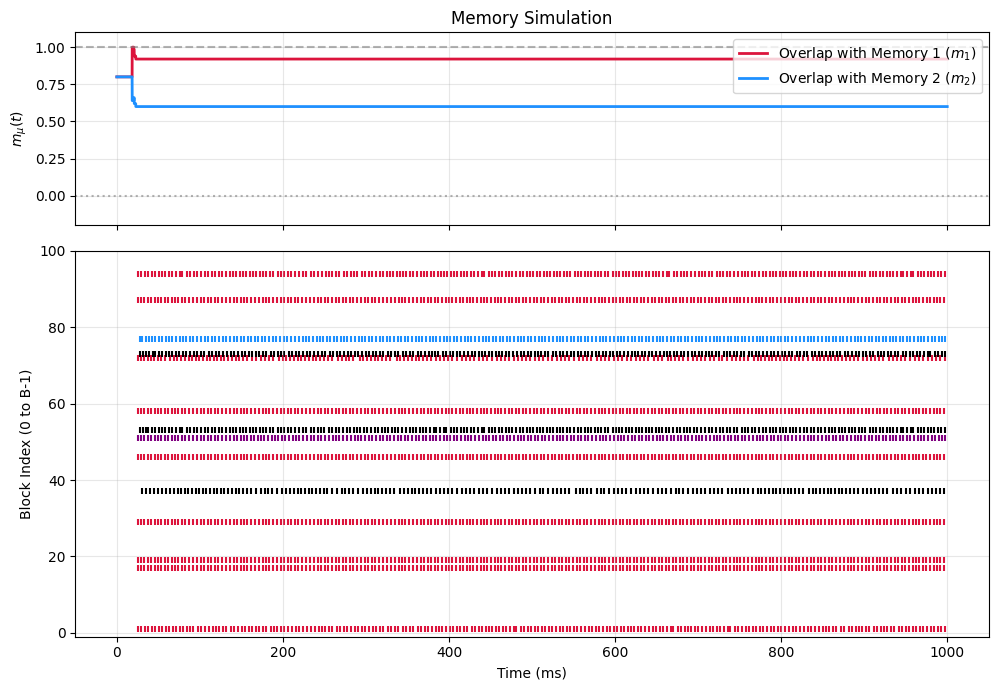

In [ ]:
# Fire two stimuli with a delay to measure response to novel information when storing current information
T_total_ms=1000
schedule_delayed = [(0.0, 30.0, 0, 1.0),  (150.0, 180.0, 1, 2.5)]      # Stimulate Memory 1 at 30 ms and Stimulate Memory 2 after 150 ms]
time, spike_times, rec_times, recorded_V_out = run_simulation(T_total_ms, dt, B, patterns, schedule_delayed, params, A_el, A_ch, idx)
plot_experiment_results(time, spike_times, patterns, title="Memory Simulation")

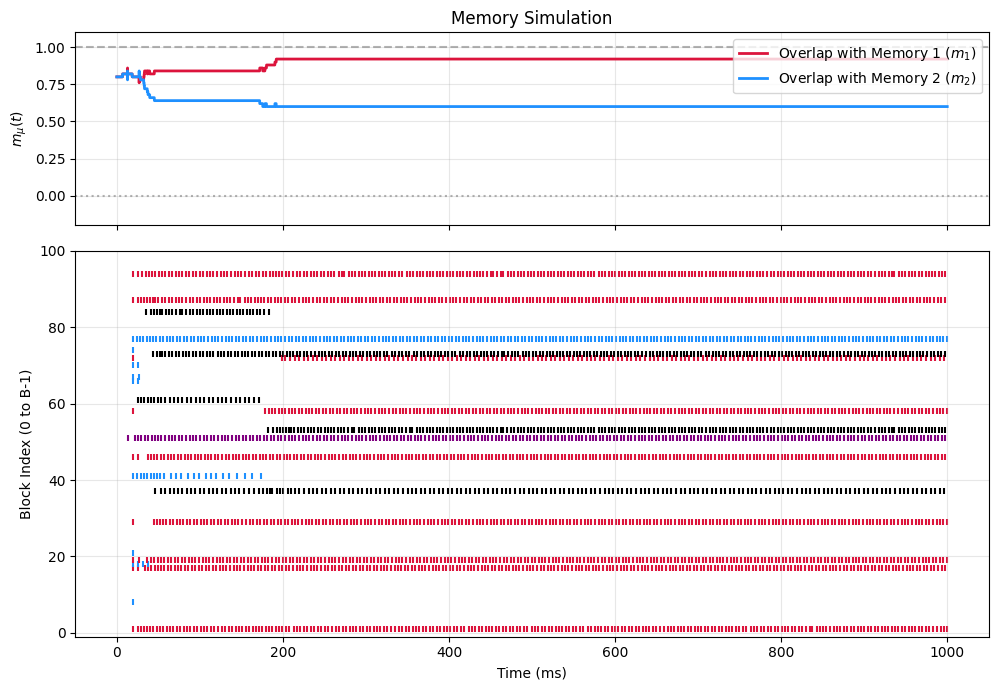

In [ ]:
# Fire two stimuli at once to sense capability to store multiple memories - notice the cells that get dragged into the limit cycle
T_total_ms=1000
schedule_delayed = [(0.0, 30.0, 0, 1.0),  (0.0, 30.0, 1, 1.0)]      # Stimulate Memory 1 at 30 ms and Stimulate Memory 2 after 150 ms]
time, spike_times, rec_times, recorded_V_out = run_simulation(T_total_ms, dt, B, patterns, schedule_delayed, params, A_el, A_ch, idx)
plot_experiment_results(time, spike_times, patterns, title="Memory Simulation")

In [ ]:
# Goal is to decompose which blocks belonged to which memories

# Identify which blocks actually spiked in the steady state
steady_spiking_blocks = set([b for b in range(B) if any(t >= 150 for t in spike_times[b])])

mem1_blocks = set(np.where(patterns[0] == 1)[0])
mem2_blocks = set(np.where(patterns[1] == 1)[0])
union_blocks = mem1_blocks.union(mem2_blocks)
intersection_blocks = mem1_blocks.intersection(mem2_blocks)

print("Total blocks in Memory 1:", len(mem1_blocks))
print("Total blocks in Memory 2:", len(mem2_blocks))
print("Total in Union (all candidate blocks):", len(union_blocks))
print("Blocks actually active in mixed attractor:", len(steady_spiking_blocks))

# Check for dropout or spurious recruitments
dropped_blocks = union_blocks - steady_spiking_blocks
spurious_blocks = steady_spiking_blocks - union_blocks

print("Dropped blocks (suppressed by competition):", dropped_blocks)
print("Spurious blocks (dragged in by cross-talk):", spurious_blocks)

# Calculate firing rate (spikes / sec) in steady state (last 100 ms)
for b in sorted(steady_spiking_blocks):
    n_spikes = sum(1 for t in spike_times[b] if t >= 150)
    rate = n_spikes / 0.1  # Hz
    cell_label = "SHARED" if b in intersection_blocks else ("MEM1" if b in mem1_blocks else ("MEM2" if b in mem2_blocks else "SPURIOUS"))
    print(f"Block {b:2d} ({cell_label:8s}): {rate:5.1f} Hz")


Total blocks in Memory 1: 10
Total blocks in Memory 2: 10
Total in Union (all candidate blocks): 18
Blocks actually active in mixed attractor: 17
Dropped blocks (suppressed by competition): {np.int64(71), np.int64(59), np.int64(15), np.int64(57), np.int64(27), np.int64(92), np.int64(93), np.int64(62)}
Spurious blocks (dragged in by cross-talk): {26, 72, 12, 51, 21, 90, 31}
Block  4 (MEM2    ): 230.0 Hz
Block 12 (SPURIOUS): 240.0 Hz
Block 13 (MEM2    ): 230.0 Hz
Block 18 (SHARED  ): 230.0 Hz
Block 20 (MEM1    ): 230.0 Hz
Block 21 (SPURIOUS): 230.0 Hz
Block 24 (MEM1    ): 230.0 Hz
Block 26 (SPURIOUS):  10.0 Hz
Block 31 (SPURIOUS): 230.0 Hz
Block 43 (MEM1    ): 230.0 Hz
Block 45 (MEM2    ): 240.0 Hz
Block 49 (SHARED  ): 240.0 Hz
Block 51 (SPURIOUS): 230.0 Hz
Block 68 (MEM2    ): 230.0 Hz
Block 72 (SPURIOUS): 240.0 Hz
Block 87 (MEM1    ): 230.0 Hz
Block 90 (SPURIOUS): 240.0 Hz


In [ ]:
# Goal is to decode which memories are in the composite limit cycle - as you can see it is difficult if neurons are shared in firing patterns
from scipy.optimize import nnls

# 1. Extract steady-state firing vector from your simulation (last 50 ms)
y_observed = np.zeros(B)
for b in range(B):
    # Fraction of time block b was active in steady state
    recent_spikes = [t for t in spike_times[b] if t >= 150]
    if len(recent_spikes) > 0:
        y_observed[b] = 1.0  # or use firing rate

# 2. Spectral Unmixing against all P=70 stored patterns
from sklearn.linear_model import Lasso

# alpha is the sparsity knob (lambda)
lasso = Lasso(alpha=0.03, positive=True, fit_intercept=False)
lasso.fit(patterns.T, y_observed)

weights_lasso = lasso.coef_

top_sparse = np.argsort(weights_lasso)[::-1][:5]
print("--- Sparse Memory Decoding ---")
for rank, idx in enumerate(top_sparse):
    if weights_lasso[idx] > 0.001:
        print(f"Rank {rank+1}: Memory {idx:2d} | Inferred Weight: {weights_lasso[idx]:.3f}")



--- Sparse Memory Decoding ---
Rank 1: Memory 15 | Inferred Weight: 0.320
Rank 2: Memory 16 | Inferred Weight: 0.178
Rank 3: Memory 42 | Inferred Weight: 0.166
Rank 4: Memory  1 | Inferred Weight: 0.165
Rank 5: Memory  0 | Inferred Weight: 0.084


# Debug Area

In [ ]:
def run_simulation(T_total_ms, dt, B, patterns, stim_schedule, params, A_el, A_ch, idx, inspect_block=39):
    N = 5 * B
    steps = int(T_total_ms / dt)
    time = np.linspace(0, T_total_ms, steps)

    # Initial conditions
    V = np.full(N, -70.0)
    m = np.zeros(N)
    h = np.zeros(N)
    n = np.zeros(N)
    p = np.zeros(N)
    q = np.zeros(N)
    s = np.zeros(N)
    r = np.zeros(N)

    A_el_sum = np.sum(A_el, axis=1)
    spike_times = {b: [] for b in range(B)}

    # Voltage recorders for debugging signal propagation inside inspect_block
    n_rec = steps // 10
    rec_times = time[::10]
    rec_V_ib   = np.zeros(n_rec)
    rec_V_rsa1 = np.zeros(n_rec)
    rec_V_rsa2 = np.zeros(n_rec)
    rec_V_out  = np.zeros(n_rec)

    V_prev = V.copy()

    for step in range(steps):
        t_now = step * dt

        # 1. External stimulus I_in
        I_in = np.zeros(N)
        for (t_start, t_end, pat_idx, amp) in stim_schedule:
            if t_start <= t_now <= t_end:
                active_blocks = np.where(patterns[pat_idx] == 1)[0]
                for b in active_blocks:
                    I_in[idx(b, 0)] += amp

        # 2. Synaptic currents
        I_el = (A_el @ V) - (A_el_sum * V)
        s_chem = A_ch @ (r * params['V_syn'])
        g_chem = A_ch @ r
        I_ch = s_chem - g_chem * V

        # 3. Euler integration
        V_prev[:] = V
        V, m, h, n, p, q, s, r = euler_step_hh(
            V, m, h, n, p, q, s, r, I_in, I_el, I_ch, params, dt=dt
        )

        # 4. Spike detection on output neurons (cell_type 4)
        for b in range(B):
            out_i = idx(b, 4)
            if V_prev[out_i] <= 0.0 and V[out_i] > 0.0:
                spike_times[b].append(t_now)

        # 5. Record voltages inside inspect_block every 10 steps (0.1 ms)
        if step % 10 == 0:
            ridx = step // 10
            rec_V_ib[ridx]   = V[idx(inspect_block, 0)]  # IB (input)
            rec_V_rsa1[ridx] = V[idx(inspect_block, 1)]  # RSA1 (integrator)
            rec_V_rsa2[ridx] = V[idx(inspect_block, 2)]  # RSA2 (transmitter)
            rec_V_out[ridx]  = V[idx(inspect_block, 4)]  # RSA_out (output)

    debug_traces = {
        'IB': rec_V_ib,
        'RSA1': rec_V_rsa1,
        'RSA2': rec_V_rsa2,
        'OUT': rec_V_out
    }

    return time, spike_times, rec_times, debug_traces



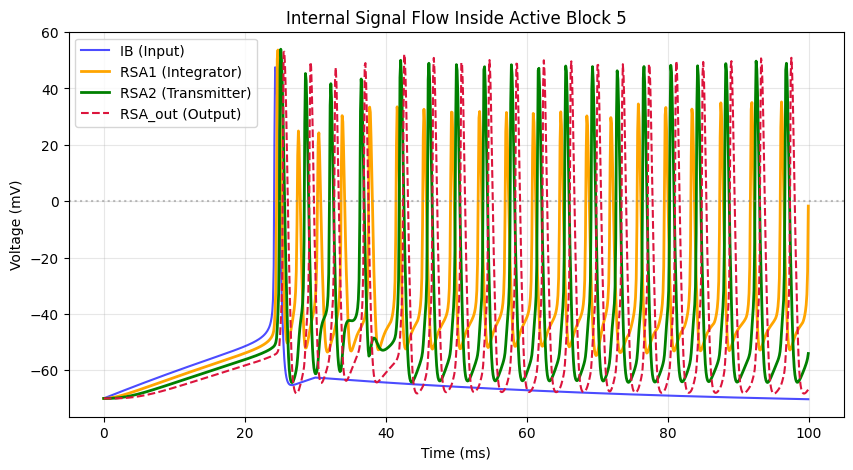

In [ ]:
import matplotlib.pyplot as plt

# Pick an active block to inspect from Memory 0
active_blocks = np.where(patterns[0] == 1)[0]
b_inspect = active_blocks[0]

time, spike_times, rec_times, traces = run_simulation(
    T_total_ms=100.0, dt=0.01, B=B, patterns=patterns,
    stim_schedule=schedule_mem1, params=params,
    A_el=A_el, A_ch=A_ch, idx=idx, inspect_block=b_inspect
)

# Plot all 4 cells inside that single block
plt.figure(figsize=(10, 5))
plt.plot(rec_times, traces['IB'],   label='IB (Input)', color='blue', alpha=0.7)
plt.plot(rec_times, traces['RSA1'], label='RSA1 (Integrator)', color='orange', lw=2)
plt.plot(rec_times, traces['RSA2'], label='RSA2 (Transmitter)', color='green', lw=2)
plt.plot(rec_times, traces['OUT'],  label='RSA_out (Output)', color='crimson', linestyle='--')
plt.axhline(0.0, color='gray', linestyle=':', alpha=0.5)
plt.title(f"Internal Signal Flow Inside Active Block {b_inspect}")
plt.ylabel("Voltage (mV)")
plt.xlabel("Time (ms)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
